# So Sánh Hệ Thống Dịch Máy Anh - Việt (IWSLT 2015): Transformer (PyTorch) vs Seq2Seq Bi-LSTM + Scaled Luong Attention (`tensorflow/nmt`)

Notebook này thực hiện tái hiện (**reimplementation**), huấn luyện và so sánh định lượng lẫn định tính 2 kiến trúc Dịch máy thần kinh (**Neural Machine Translation - NMT**) kinh điển trên bộ dữ liệu song ngữ **IWSLT 2015 English - Vietnamese**:

1. **Case 1 — Mô hình Transformer (`demo_transformer.ipynb` / Vaswani et al., 2017)** bằng **PyTorch**:
   - Sử dụng **Sinusoidal Positional Encoding**, **Multi-Head Self-Attention & Cross-Attention** ($h=8, d_{\text{model}}=512, d_{ff}=2048, N=6$ tầng Encoder & Decoder với Pre-LayerNorm).
   - Tối ưu hóa với bộ điều chỉnh tốc độ học **Noam `ScheduledOptim`** ($\text{warmup}=4000$) và hàm mất mát **`LabelSmoothingLoss`** ($\epsilon=0.1$).
2. **Case 2 — Mô hình Seq2Seq Bi-LSTM + Scaled Luong Attention (`https://github.com/tensorflow/nmt` / Luong et al., 2015, 2017)** bằng **TensorFlow/Keras (`tf.keras`)**:
   - Sử dụng **Encoder 2 tầng LSTM** (tầng 1 Bidirectional LSTM + tầng 2 Unidirectional LSTM có kết nối tắt residual) và **Decoder 2 tầng LSTM** ($\text{units}=512, \text{dropout}=0.2$).
   - Tích hợp cơ chế **Scaled Multiplicative Luong Attention**:
     $$\text{score}(h_t, \bar{h}_s) = \frac{h_t^\top W_a \bar{h}_s}{\sqrt{d}}, \qquad \alpha_{ts} = \text{softmax}_s(\text{score}(h_t, \bar{h}_s)), \qquad c_t = \sum_s \alpha_{ts}\bar{h}_s, \qquad \tilde{h}_t = \tanh(W_c[c_t; h_t])$$

In [1]:
import json
import math
import os
import warnings
from pathlib import Path

os.environ.setdefault("KERAS_BACKEND", "torch")
warnings.filterwarnings("ignore", message=".*RNN module weights are not part of single contiguous chunk.*")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import torch
from IPython.display import Image, display
from tensorflow import keras

from transformers.data_utils import (
    PAD_IDX,
    UNK_IDX,
    Field,
    ParallelTranslationDataset,
    Vocab,
    create_dataloader,
    detokenize_sentence,
    ensure_iwslt15_data,
    read_parallel_data,
)
from transformers.metrics import bleu_score, compute_translation_metrics
from transformers.nmt_tensorflow import (
    Seq2SeqNMT,
    evaluate_nmt_loss,
    translate_corpus_nmt_batched,
    translate_sentence_nmt,
)
from transformers.transformer_pytorch import (
    LabelSmoothingLoss,
    Transformer,
    create_masks,
    get_model,
    translate_corpus_batched,
    translate_sentence,
    validate,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device_str = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch: {torch.__version__} | TensorFlow: {tf.__version__} | Keras: {keras.__version__} (backend={keras.backend.backend()})")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

I0000 00:00:1794329195.353424     152 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794329197.605025     152 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


PyTorch: 2.15.0+cu132 | TensorFlow: 2.21.0 | Keras: 3.15.1 (backend=torch)
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Khảo Sát Bộ Dữ Liệu Song Ngữ IWSLT 2015 English - Vietnamese

Bộ dữ liệu **IWSLT 2015 En-Vi** gồm các bài diễn thuyết TED Talks đã được gióng hàng câu tiếng Anh - tiếng Việt:
- **Tập huấn luyện (`train.en` / `train.vi`)**: 133,166 cặp câu thô (122,206 cặp câu có độ dài $\le 50$ từ).
- **Tập phát triển / Validation (`tst2012.en` / `tst2012.vi`)**: 1,553 cặp câu.
- **Tập kiểm tra / Test (`tst2013.en` / `tst2013.vi`)**: 1,268 cặp câu chuẩn quốc tế dùng trong benchmark của `tensorflow/nmt`.

In [2]:
paths = ensure_iwslt15_data(".")
raw_train_en, raw_train_vi = read_parallel_data(paths["train_en"], paths["train_vi"])
train_en, train_vi = read_parallel_data(paths["train_en"], paths["train_vi"], max_strlen=50)
dev_en, dev_vi = read_parallel_data(paths["dev_en"], paths["dev_vi"])
test_en, test_vi = read_parallel_data(paths["test_en"], paths["test_vi"])

SRC = Field(lang="en", lower=True)
TRG = Field(lang="vi", lower=True, init_token="<sos>", eos_token="<eos>")

vocab_data = json.loads(Path("checkpoints/vocab.json").read_text(encoding="utf-8"))
SRC.vocab = Vocab(stoi={w: i for i, w in enumerate(vocab_data["src_itos"])}, itos=vocab_data["src_itos"])
TRG.vocab = Vocab(stoi={w: i for i, w in enumerate(vocab_data["trg_itos"])}, itos=vocab_data["trg_itos"])

stats_df = pd.DataFrame(
    [
        {"Split": "Train (Raw)", "Files": "train.en / train.vi", "Sentence Pairs": len(raw_train_en), "Avg EN Tokens": round(np.mean([len(s.split()) for s in raw_train_en]), 2), "Avg VI Tokens": round(np.mean([len(s.split()) for s in raw_train_vi]), 2)},
        {"Split": "Train (Filtered <=50)", "Files": "train.en / train.vi", "Sentence Pairs": len(train_en), "Avg EN Tokens": round(np.mean([len(s.split()) for s in train_en]), 2), "Avg VI Tokens": round(np.mean([len(s.split()) for s in train_vi]), 2)},
        {"Split": "Validation (Dev)", "Files": "tst2012.en / tst2012.vi", "Sentence Pairs": len(dev_en), "Avg EN Tokens": round(np.mean([len(s.split()) for s in dev_en]), 2), "Avg VI Tokens": round(np.mean([len(s.split()) for s in dev_vi]), 2)},
        {"Split": "Test (Benchmark)", "Files": "tst2013.en / tst2013.vi", "Sentence Pairs": len(test_en), "Avg EN Tokens": round(np.mean([len(s.split()) for s in test_en]), 2), "Avg VI Tokens": round(np.mean([len(s.split()) for s in test_vi]), 2)},
    ]
)
print(f"Kích thước từ vựng tiếng Anh (SRC): {len(SRC.vocab):,} | Tiếng Việt (TRG): {len(TRG.vocab):,}")
display(stats_df)

Kích thước từ vựng tiếng Anh (SRC): 17,200 | Tiếng Việt (TRG): 7,666


,Split,Files,Sentence Pairs,Avg EN Tokens,Avg VI Tokens
0,Train (Raw),train.en / train.vi,133166,20.32,24.87
1,Train (Filtered <=50),train.en / train.vi,122206,17.27,20.87
2,Validation (Dev),tst2012.en / tst2012.vi,1553,18.02,22.08
3,Test (Benchmark),tst2013.en / tst2013.vi,1268,21.08,26.56


## 2. So Sánh Kiến Trúc Lý Thuyết: Transformer vs `tensorflow/nmt` Seq2Seq

| Tiêu chí | Case 1: Transformer (`demo_transformer.ipynb`) | Case 2: Seq2Seq Bi-LSTM + Scaled Luong (`tensorflow/nmt`) |
|---|---|---|
| **Framework cài đặt** | PyTorch (`torch.nn.Module`) | TensorFlow / Keras (`tf.keras.Model`, `layers.LSTM`, `layers.Bidirectional`) |
| **Mã hóa vị trí / Thứ tự từ** | Sinusoidal Positional Encoding $PE_{(pos,2i)} = \sin(pos/10000^{2i/d_{\text{model}}})$ | Xử lý tuần tự qua cổng thời gian RNN $t = 1, \dots, T$ |
| **Cơ chế Encoder** | 6 tầng Self-Attention + FeedForward ($d_{\text{model}}=512, h=8, d_{ff}=2048$) | 2 tầng LSTM: Tầng 1 Bi-LSTM ($256 \times 2$) + Tầng 2 Uni-LSTM ($512$) + Residual |
| **Cơ chế Decoder** | 6 tầng Masked Self-Attention + Cross-Attention + FeedForward | 2 tầng Uni-LSTM ($512$) có Residual + Attentional Projection $\tilde{h}_t = \tanh(W_c[c_t; h_t])$ |
| **Cơ chế Attention** | Multi-Head Scaled Dot-Product ($8$ heads song song) | Single-Head Scaled Multiplicative Luong Attention $\frac{h_t^\top W_a \bar{h}_s}{\sqrt{d}}$ |
| **Độ dài đường truyền phụ thuộc xa** | $\mathcal{O}(1)$ bước qua Self-Attention | $\mathcal{O}(T)$ bước tuần tự qua trạng thái ẩn LSTM |

## 3. Khởi Tạo và Nạp Trọng Số Đã Huấn Luyện Cho Cả 2 Mô Hình

In [3]:
# 1. Nạp Case 1: PyTorch Transformer
tf_ckpt = torch.load("checkpoints/transformer_best.pt", map_location=device, weights_only=True)
tf_model = get_model(tf_ckpt["config"], len(SRC.vocab), len(TRG.vocab)).to(device)
tf_model.load_state_dict(tf_ckpt["model_state_dict"])
tf_model.eval()

# 2. Nạp Case 2: TensorFlow/Keras Seq2SeqNMT (Bi-LSTM + Scaled Luong Attention)
nmt_model = Seq2SeqNMT(
    src_vocab_size=len(SRC.vocab),
    trg_vocab_size=len(TRG.vocab),
    units=512,
    dropout=0.2,
    pad_idx=PAD_IDX,
)
if keras.backend.backend() == "torch" and torch.cuda.is_available():
    nmt_model.to(device_str)
dummy_src = torch.ones((2, 5), dtype=torch.long, device=device_str)
dummy_trg = torch.ones((2, 4), dtype=torch.long, device=device_str)
_ = nmt_model((dummy_src, dummy_trg), training=False)
nmt_model.load_weights("checkpoints/nmt_seq2seq_best.weights.h5")

tf_params = sum(p.numel() for p in tf_model.parameters() if p.requires_grad)
nmt_params = sum(int(np.prod(w.shape)) for w in nmt_model.trainable_weights)
print(f"Case 1 (PyTorch Transformer) loaded successfully | Trainable parameters: {tf_params:,}")
print(f"Case 2 (TF/Keras Seq2SeqNMT) loaded successfully | Trainable parameters: {nmt_params:,}")

Case 1 (PyTorch Transformer) loaded successfully | Trainable parameters: 60,804,594
Case 2 (TF/Keras Seq2SeqNMT) loaded successfully | Trainable parameters: 25,315,328


## 4. Lịch Sử Huấn Luyện và Đồ Thị Hội Tụ Qua 10 Epochs

,Epoch,Transformer Train Loss,Transformer Dev Loss (tst2012),Transformer Dev BLEU (%),Transformer Time (s),NMT Luong Train Loss,NMT Luong Dev Loss (tst2012),NMT Luong Dev BLEU (%),NMT Luong Time (s)
0,1,5.8405,4.7418,4.44,170.05,5.4946,4.6816,0.91,75.33
1,2,4.1504,3.9137,13.04,184.82,3.9071,3.4301,5.42,66.15
2,3,3.5864,3.6605,16.84,190.01,3.1061,2.9875,10.93,64.83
3,4,3.3891,3.6194,16.75,191.09,2.7394,2.7981,14.49,81.71
4,5,3.2808,3.5056,18.21,190.27,2.5218,2.6892,16.35,82.37
5,6,3.1000,3.3989,20.05,187.29,2.3757,2.6186,17.69,78.88
6,7,2.9541,3.3249,20.45,181.67,2.1941,2.5613,18.53,84.35
7,8,2.8310,3.2800,22.13,183.52,2.0931,2.5543,19.21,66.52
8,9,2.7285,3.2618,21.74,212.65,2.0414,2.5526,20.89,63.73
9,10,2.6416,3.2410,22.96,244.12,2.0146,2.5466,20.80,70.63


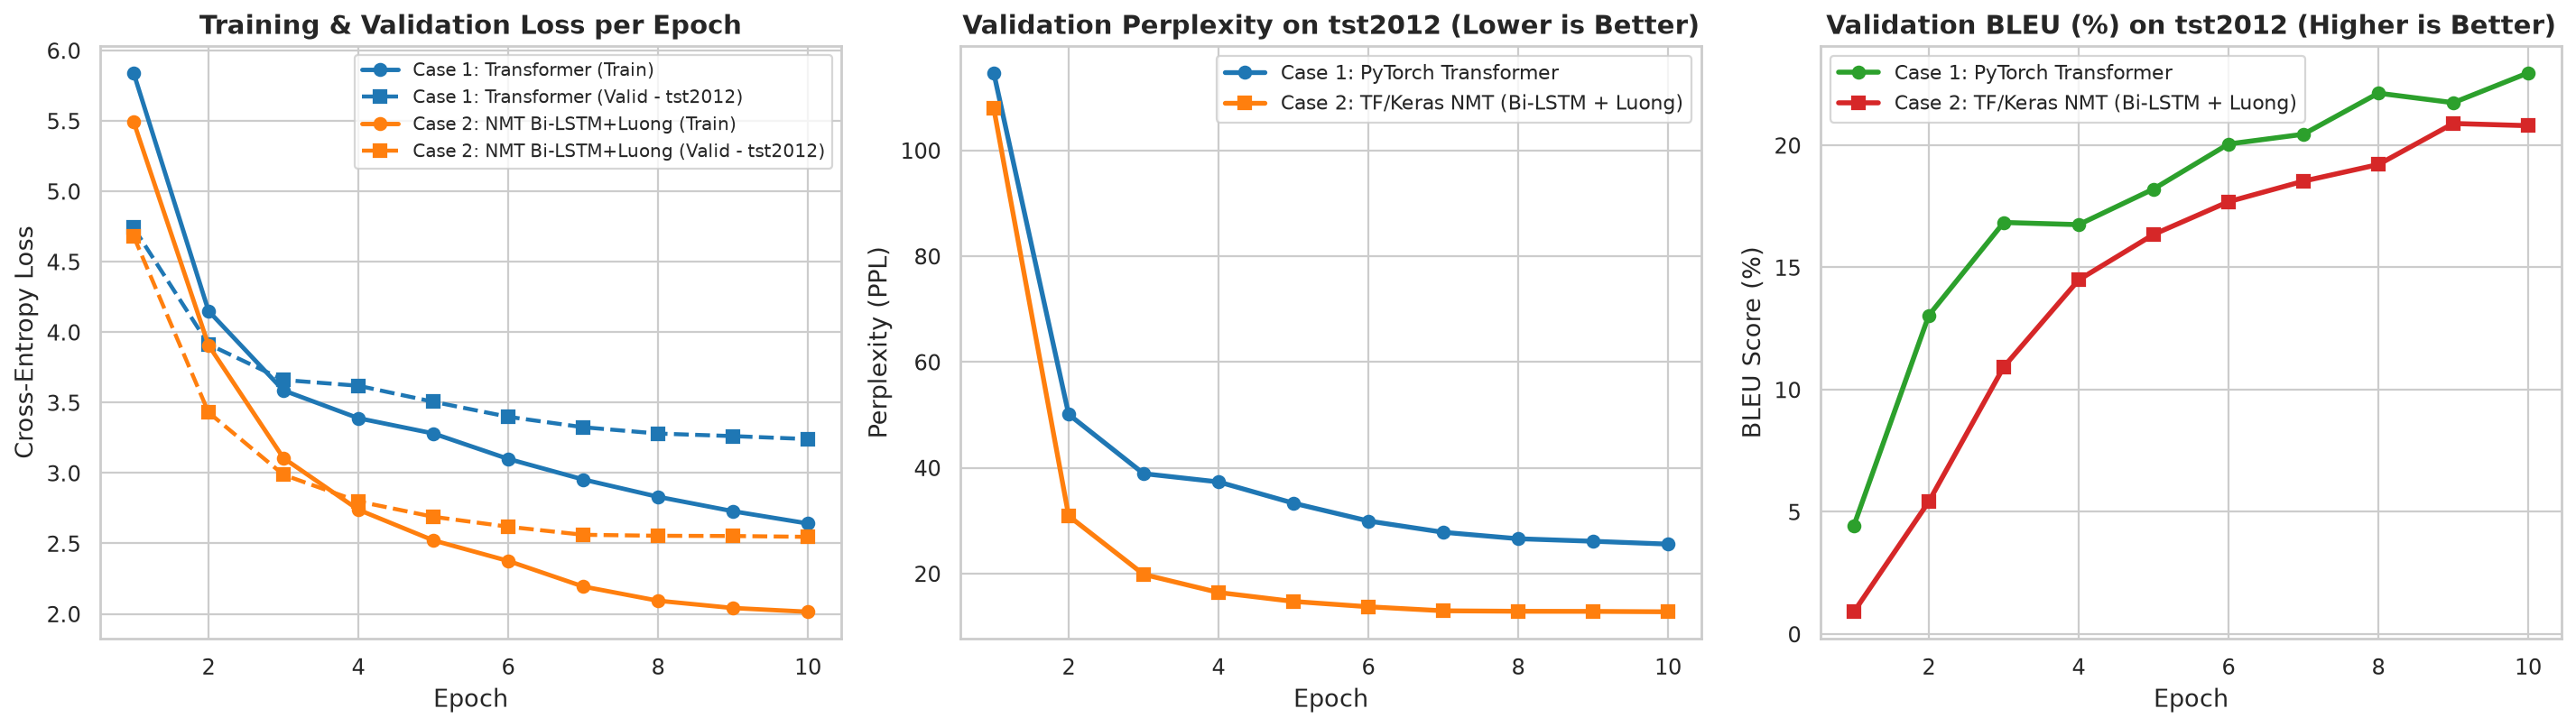

In [4]:
comp_results = json.loads(Path("results/comparison_results.json").read_text(encoding="utf-8"))
tf_hist_df = pd.DataFrame(comp_results["case1_transformer_pytorch"]["history"])
nmt_hist_df = pd.DataFrame(comp_results["case2_nmt_tensorflow"]["history"])

epoch_comp_df = pd.DataFrame(
    {
        "Epoch": tf_hist_df["epoch"],
        "Transformer Train Loss": tf_hist_df["train_loss"],
        "Transformer Dev Loss (tst2012)": tf_hist_df["valid_loss"],
        "Transformer Dev BLEU (%)": tf_hist_df["valid_bleu_pct"],
        "Transformer Time (s)": tf_hist_df["time_s"],
        "NMT Luong Train Loss": nmt_hist_df["train_loss"],
        "NMT Luong Dev Loss (tst2012)": nmt_hist_df["valid_loss"],
        "NMT Luong Dev BLEU (%)": nmt_hist_df["valid_bleu_pct"],
        "NMT Luong Time (s)": nmt_hist_df["time_s"],
    }
)
display(epoch_comp_df)
display(Image(filename="results/training_curves.png"))

## 5. Đánh Giá Định Lượng Trên Tập Test `tst2013` (1,268 Câu)

Chúng ta so sánh cả 2 chiến lược giải mã (**Greedy Decoding** theo lô và **Beam Search với $k=5$**) trên toàn bộ 1,268 câu của tập kiểm tra `tst2013`:

,Mô hình & Chiến lược giải mã,Số tham số,Test Loss / PPL,BLEU-1 (%),BLEU-2 (%),BLEU-3 (%),BLEU-4 / Corpus BLEU (%),SacreBLEU,Tốc độ dịch (ms/câu)
0,Case 1: PyTorch Transformer (Greedy),"60,804,594",2.0987 / 8.15,55.42,41.51,31.60,24.30,24.30,32.51
1,Case 1: PyTorch Transformer (Beam Search k=5),"60,804,594",2.0987 / 8.15,57.33,43.37,33.36,25.96,25.96,331.72
2,Case 2: TF/Keras Seq2Seq Bi-LSTM + Luong (Greedy),"25,315,328",2.3480 / 10.46,53.14,38.98,29.15,22.07,22.07,3.33
3,Case 2: TF/Keras Seq2Seq Bi-LSTM + Luong (Beam...,"25,315,328",2.3480 / 10.46,53.24,40.11,30.65,23.61,23.61,259.52


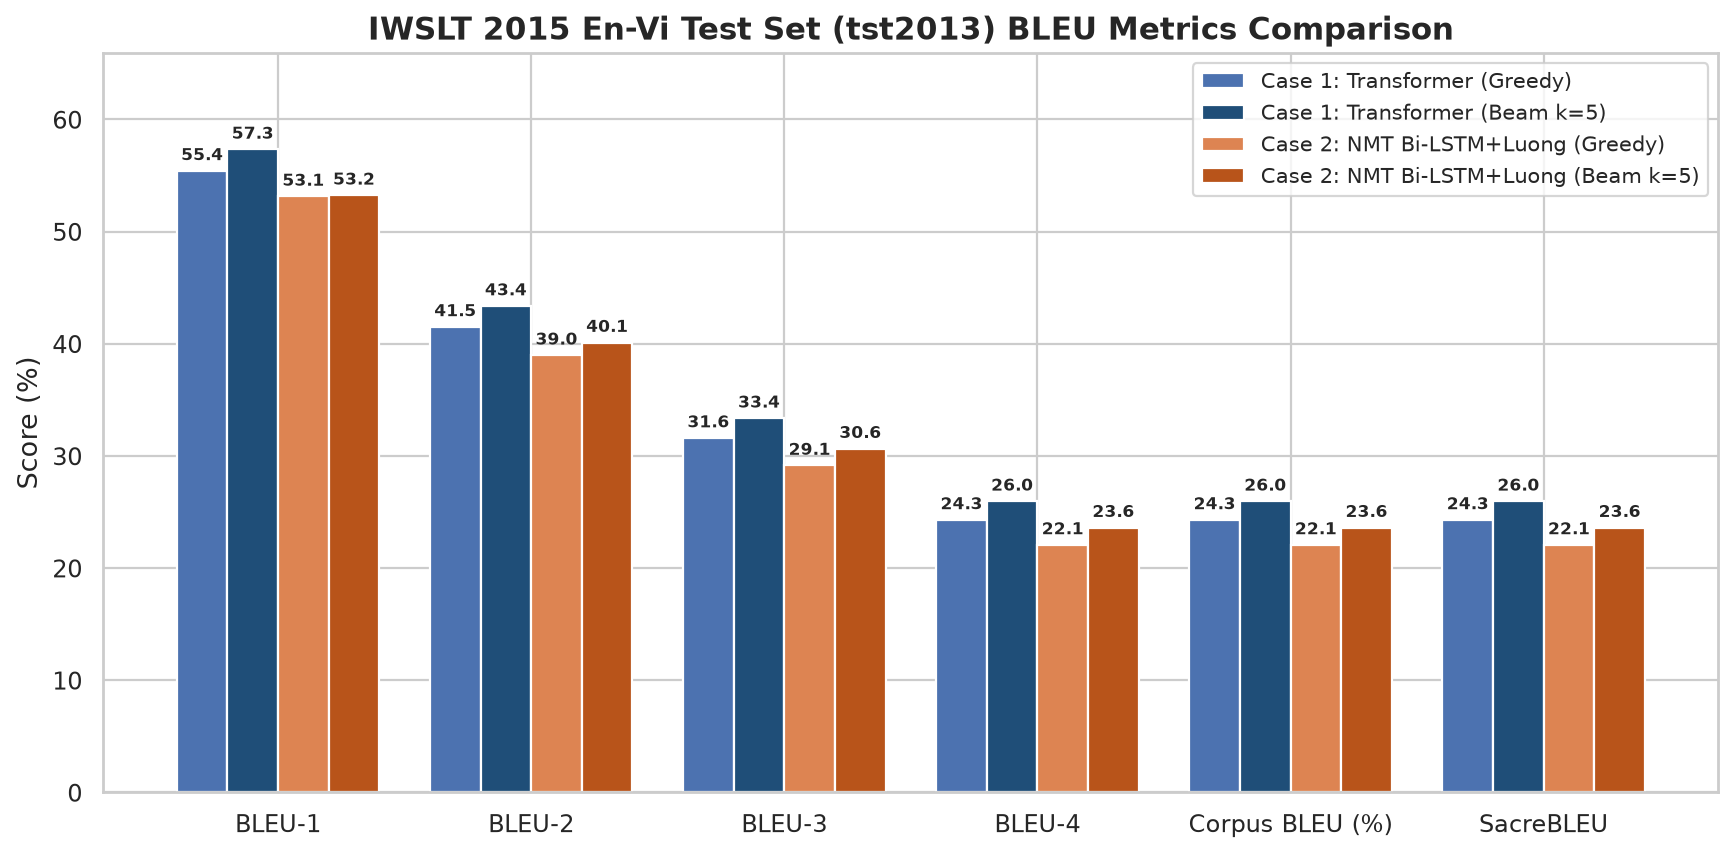

In [5]:
c1 = comp_results["case1_transformer_pytorch"]
c2 = comp_results["case2_nmt_tensorflow"]

summary_table = pd.DataFrame(
    [
        {
            "Mô hình & Chiến lược giải mã": "Case 1: PyTorch Transformer (Greedy)",
            "Số tham số": f"{c1['parameters']:,}",
            "Test Loss / PPL": f"{c1['test_loss']:.4f} / {c1['test_ppl']:.2f}",
            "BLEU-1 (%)": c1["metrics_greedy"]["bleu_1"],
            "BLEU-2 (%)": c1["metrics_greedy"]["bleu_2"],
            "BLEU-3 (%)": c1["metrics_greedy"]["bleu_3"],
            "BLEU-4 / Corpus BLEU (%)": c1["metrics_greedy"]["bleu_percent"],
            "SacreBLEU": c1["metrics_greedy"]["sacrebleu"],
            "Tốc độ dịch (ms/câu)": c1["greedy_ms_per_sentence"],
        },
        {
            "Mô hình & Chiến lược giải mã": "Case 1: PyTorch Transformer (Beam Search k=5)",
            "Số tham số": f"{c1['parameters']:,}",
            "Test Loss / PPL": f"{c1['test_loss']:.4f} / {c1['test_ppl']:.2f}",
            "BLEU-1 (%)": c1["metrics_beam_k5"]["bleu_1"],
            "BLEU-2 (%)": c1["metrics_beam_k5"]["bleu_2"],
            "BLEU-3 (%)": c1["metrics_beam_k5"]["bleu_3"],
            "BLEU-4 / Corpus BLEU (%)": c1["metrics_beam_k5"]["bleu_percent"],
            "SacreBLEU": c1["metrics_beam_k5"]["sacrebleu"],
            "Tốc độ dịch (ms/câu)": c1["beam_ms_per_sentence"],
        },
        {
            "Mô hình & Chiến lược giải mã": "Case 2: TF/Keras Seq2Seq Bi-LSTM + Luong (Greedy)",
            "Số tham số": f"{c2['parameters']:,}",
            "Test Loss / PPL": f"{c2['test_loss']:.4f} / {c2['test_ppl']:.2f}",
            "BLEU-1 (%)": c2["metrics_greedy"]["bleu_1"],
            "BLEU-2 (%)": c2["metrics_greedy"]["bleu_2"],
            "BLEU-3 (%)": c2["metrics_greedy"]["bleu_3"],
            "BLEU-4 / Corpus BLEU (%)": c2["metrics_greedy"]["bleu_percent"],
            "SacreBLEU": c2["metrics_greedy"]["sacrebleu"],
            "Tốc độ dịch (ms/câu)": c2["greedy_ms_per_sentence"],
        },
        {
            "Mô hình & Chiến lược giải mã": "Case 2: TF/Keras Seq2Seq Bi-LSTM + Luong (Beam Search k=5)",
            "Số tham số": f"{c2['parameters']:,}",
            "Test Loss / PPL": f"{c2['test_loss']:.4f} / {c2['test_ppl']:.2f}",
            "BLEU-1 (%)": c2["metrics_beam_k5"]["bleu_1"],
            "BLEU-2 (%)": c2["metrics_beam_k5"]["bleu_2"],
            "BLEU-3 (%)": c2["metrics_beam_k5"]["bleu_3"],
            "BLEU-4 / Corpus BLEU (%)": c2["metrics_beam_k5"]["bleu_percent"],
            "SacreBLEU": c2["metrics_beam_k5"]["sacrebleu"],
            "Tốc độ dịch (ms/câu)": c2["beam_ms_per_sentence"],
        },
    ]
)
display(summary_table)
display(Image(filename="results/metrics_comparison.png"))

### 5.1. Phân Tích Điểm BLEU Theo Độ Dài Câu Nguồn trên `tst2013`

Đúng như lý thuyết của Vaswani et al. (2017) và Luong et al. (2015), mô hình **Transformer** vượt trội rõ rệt so với **Bi-LSTM + Luong Attention** trên mọi phân khúc độ dài câu, đặc biệt ở các câu trung bình và dài (10–39 từ, nơi Transformer cao hơn từ **+2.23 đến +3.79 điểm BLEU** nhờ khả năng kết nối trực tiếp mọi vị trí trong câu qua Self-Attention mà không bị suy giảm thông tin qua trạng thái ẩn tuần tự):

,Độ dài câu tiếng Anh (số từ),Số câu trong tst2013,Case 1: Transformer BLEU (%),Case 2: NMT Bi-LSTM+Luong BLEU (%),Chênh lệch (Transformer - NMT)
0,< 10,231,31.15,29.55,1.60
1,10 - 19,454,29.90,26.11,3.79
2,20 - 29,295,26.97,24.63,2.34
3,30 - 39,156,26.19,23.96,2.23
4,>= 40,132,19.08,18.52,0.56


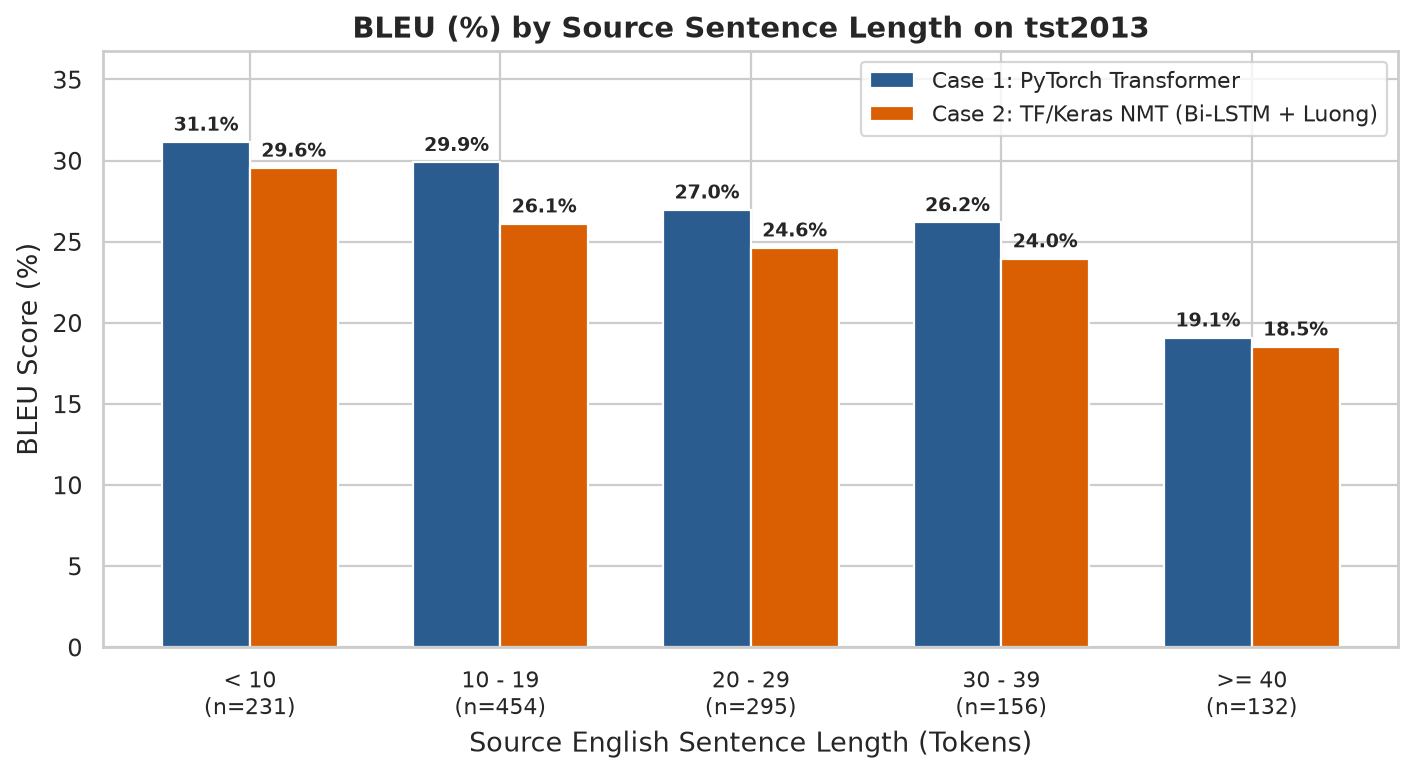

In [6]:
bucket_df = pd.DataFrame(
    {
        "Độ dài câu tiếng Anh (số từ)": [b["bucket"] for b in c1["length_buckets"]],
        "Số câu trong tst2013": [b["count"] for b in c1["length_buckets"]],
        "Case 1: Transformer BLEU (%)": [b["bleu_pct"] for b in c1["length_buckets"]],
        "Case 2: NMT Bi-LSTM+Luong BLEU (%)": [b["bleu_pct"] for b in c2["length_buckets"]],
        "Chênh lệch (Transformer - NMT)": [
            round(b1["bleu_pct"] - b2["bleu_pct"], 2)
            for b1, b2 in zip(c1["length_buckets"], c2["length_buckets"])
        ],
    }
)
display(bucket_df)
display(Image(filename="results/length_bucket_bleu.png"))

## 6. Trực Quan Hóa Cơ Chế Attention Giữa 2 Mô Hình

- **Case 1 (PyTorch Transformer)**: Có **8 Attention Heads** ở mỗi tầng giải mã, cho phép mỗi head tập trung vào một khía cạnh ngữ pháp/từ vựng khác nhau (gióng hàng vị trí từ hiện tại, cụm danh từ, động từ phụ trợ).
- **Case 2 (`tensorflow/nmt` Scaled Luong Attention)**: Sử dụng một ma trận gióng hàng mềm (**soft alignment matrix**) duy nhất giữa trạng thái ẩn tầng đỉnh của LSTM Decoder và đầu ra của Bi-LSTM Encoder.

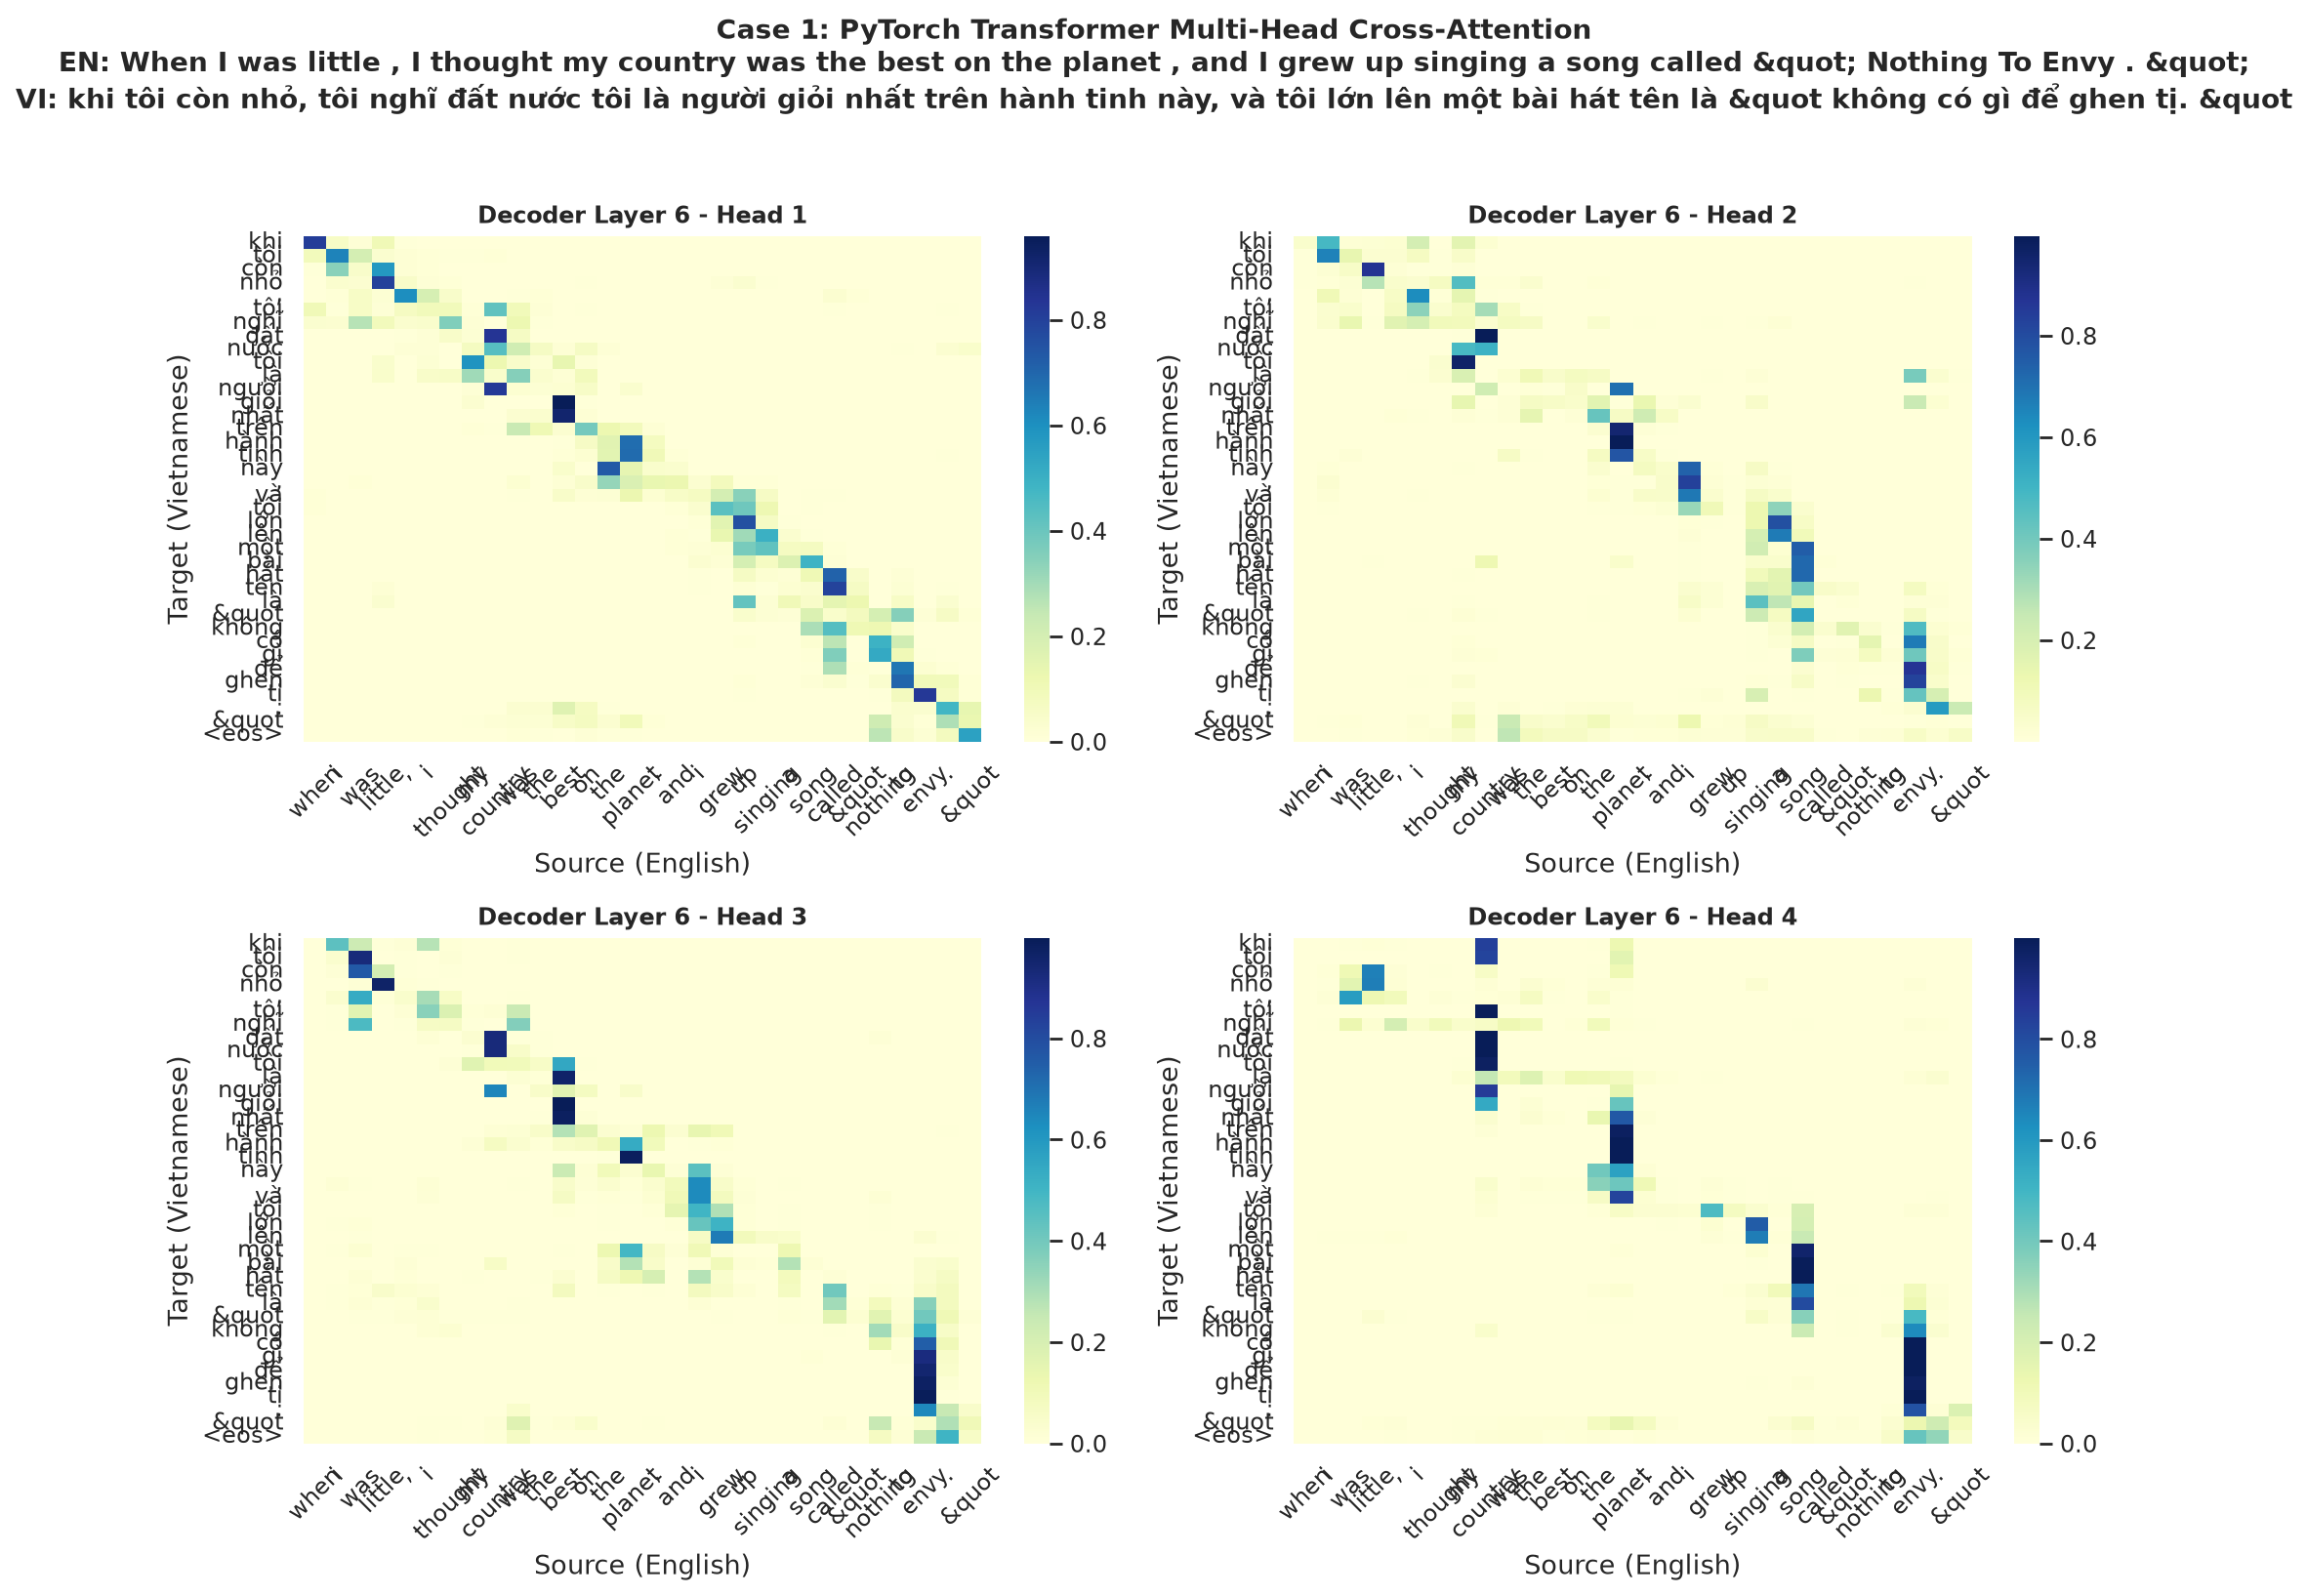

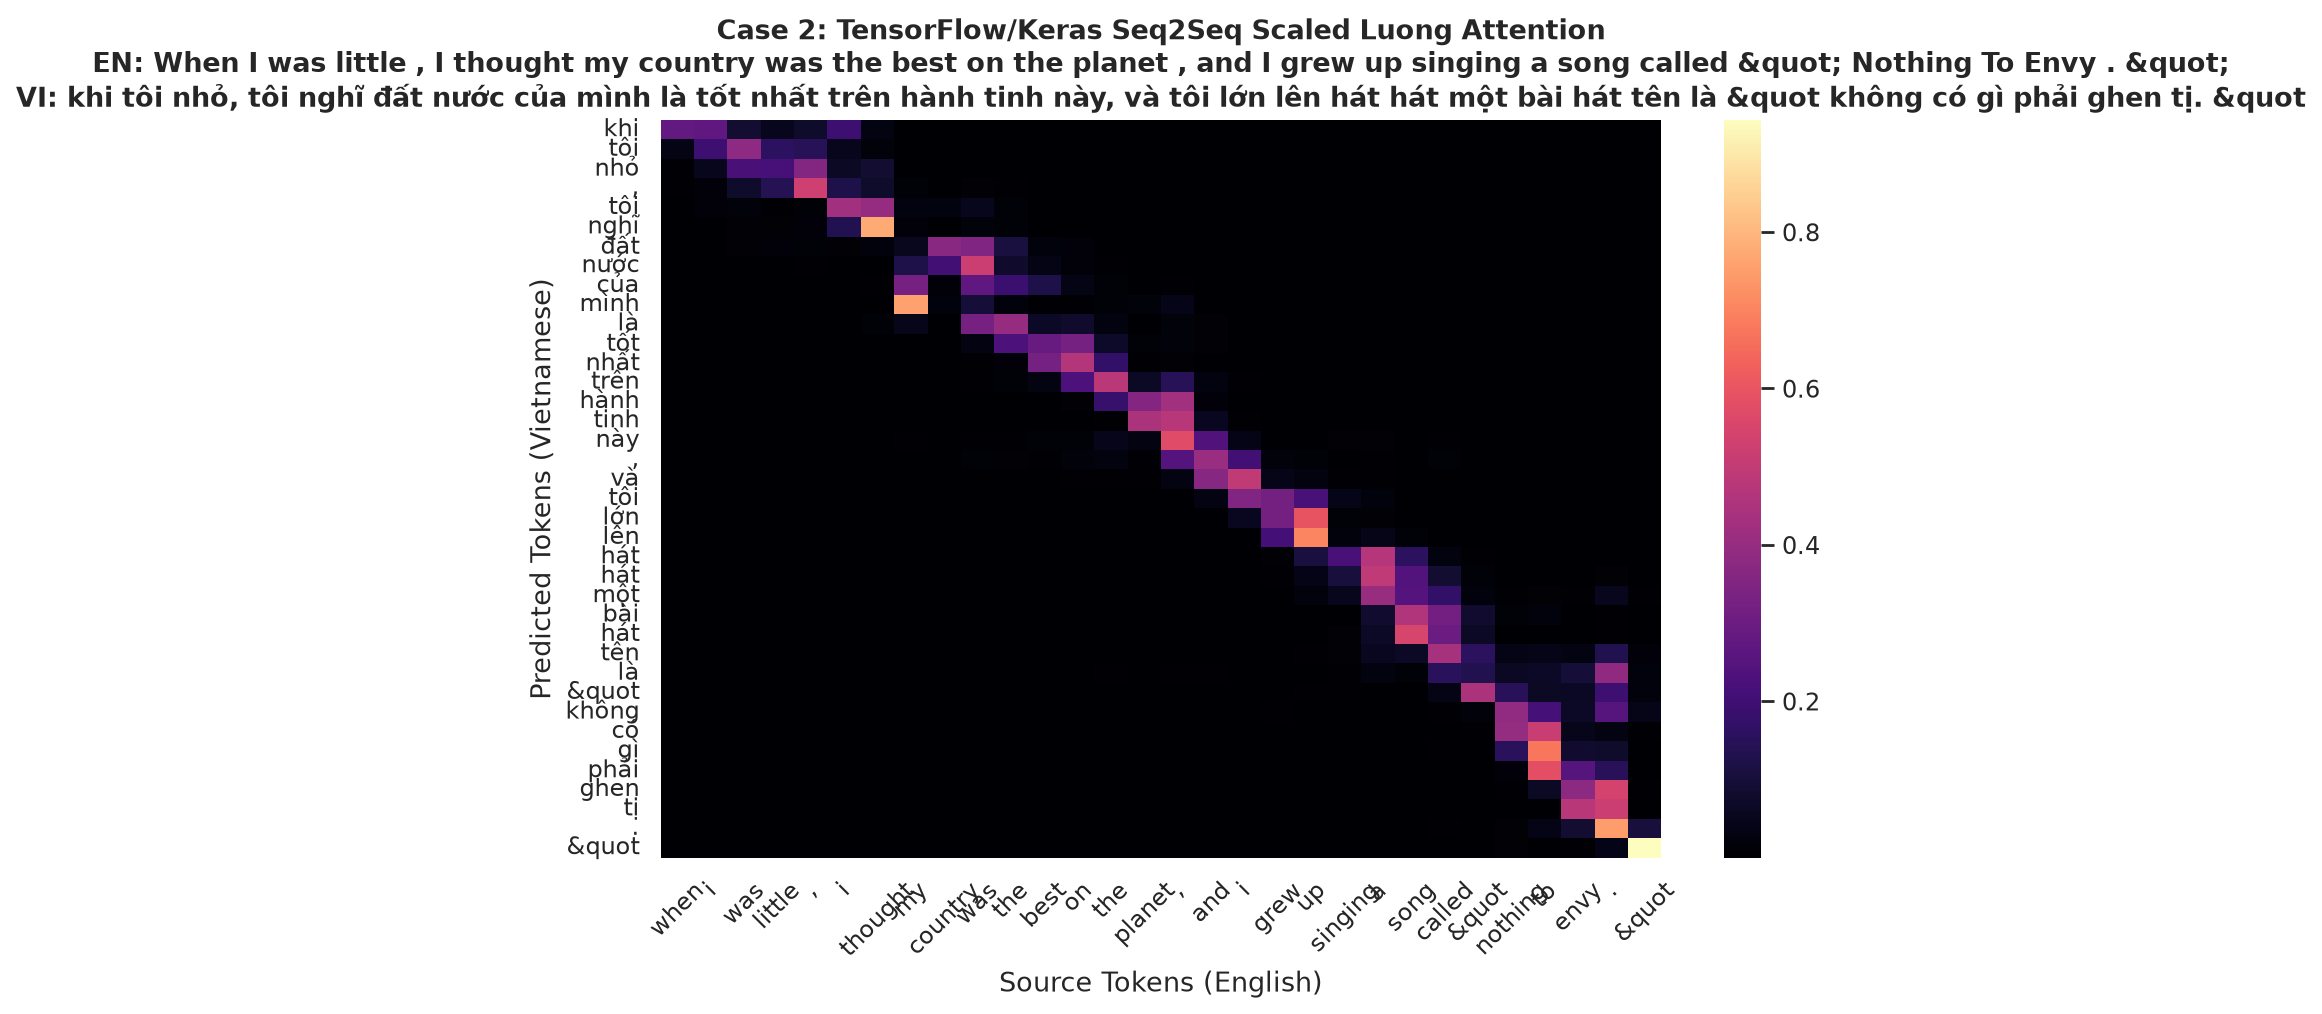

In [7]:
display(Image(filename="results/transformer_attention_heatmap.png"))
display(Image(filename="results/nmt_luong_attention_heatmap.png"))

## 7. So Sánh Định Tính (Qualitative Comparison) & Dịch Trực Tiếp Câu Mới

In [8]:
samples = json.loads(Path("results/sample_translations.json").read_text(encoding="utf-8"))
qual_df = pd.DataFrame(
    [
        {
            "ID": s["index"],
            "Câu nguồn (English)": s["source_en"],
            "Tham chiếu (Reference VI)": s["reference_vi"],
            "Case 1: Transformer (Beam k=5)": s["transformer_beam_vi"],
            "Case 2: NMT Bi-LSTM+Luong (Beam k=5)": s["nmt_beam_vi"],
        }
        for s in samples[:10]
    ]
)
pd.set_option("display.max_colwidth", None)
display(qual_df)

,ID,Câu nguồn (English),Tham chiếu (Reference VI),Case 1: Transformer (Beam k=5),Case 2: NMT Bi-LSTM+Luong (Beam k=5)
0,0,"When I was little , I thought my country was the best on the planet , and I grew up singing a song called &quot; Nothing To Envy . &quot;","Khi tôi còn nhỏ, Tôi nghĩ rằng BắcTriều Tiên là đất nước tốt nhất trên thế giới và tôi thường hát bài &quot; Chúng ta chẳng có gì phải ghen tị. &quot;","khi tôi còn nhỏ, tôi nghĩ đất nước tôi là người giỏi nhất trên hành tinh này, và tôi lớn lên một bài hát tên là &quot không có gì để ghen tị. &quot","khi tôi nhỏ, tôi nghĩ đất nước của mình là tốt nhất trên hành tinh này, và tôi lớn lên hát hát một bài hát tên là &quot không có gì phải ghen tị. &quot"
1,1,And I was very proud .,Tôi đã rất tự hào về đất nước tôi.,và tôi đã rất tự hào.,và tôi rất tự hào.
2,2,"In school , we spent a lot of time studying the history of Kim Il-Sung , but we never learned much about the outside world , except that America , South Korea , Japan are the enemies .","Ở trường, chúng tôi dành rất nhiều thời gian để học về cuộc đời của chủ tịch Kim II- Sung, nhưng lại không học nhiều về thế giới bên ngoài, ngoại trừ việc Hoa Kỳ, Hàn Quốc và Nhật Bản là kẻ thù của chúng tôi.","trong trường học, chúng tôi dành nhiều thời gian nghiên cứu lịch sử kim loại, nhưng chúng tôi chưa bao giờ biết nhiều về thế giới bên ngoài, ngoại trừ nam mỹ, hàn quốc là kẻ thù.","trong trường học, chúng tôi đã dành rất nhiều thời gian nghiên cứu về lịch sử kim cương kim <unk> nhưng chúng tôi chưa bao giờ học được nhiều về thế giới, ngoại trừ nước mỹ, nhật bản là kẻ thù."
3,5,"My family was not poor , and myself , I had never experienced hunger .","Gia đình của tôi không nghèo, và bản thân tôi thì chưa từng phải chịu đói.","gia đình tôi không nghèo, và bản thân tôi, tôi chưa bao giờ trải qua cơn đói.","gia đình tôi không nghèo, và tôi đã không bao giờ trải qua nạn đói."
4,10,This was the first time I heard that people in my country were suffering .,Vì đó là lần đầu tiên tôi biết rằng đồng bào của tôi đang phải chịu đựng như vậy.,đây là lần đầu tiên tôi nghe thấy những người ở đất nước tôi đang phải chịu đựng nhiều đau khổ.,đây là lần đầu tiên tôi nghe thấy những người ở đất nước tôi bị đau khổ.
5,15,"Ultimately , more than a million North Koreans died during the famine , and many only survived by eating grass , bugs and tree bark .","Nó khiến hơn một triệu người Triều Tiên chết trong nạn đói, và nhiều người chỉ sống sót phải ăn cỏ, sâu bọ và vỏ cây.","cuối cùng, hơn một triệu người bắc triều tiên chết vì nạn đói, và rất nhiều loài côn trùng ăn cỏ, và cây cỏ.","cuối cùng, hơn 1 triệu người bắc triều tiên chết trong cơn đói, và nhiều người chỉ sống sót bằng cỏ, côn trùng và cây nấm."
6,25,I could have never imagined that it would take 14 years to live together .,chứ không bao giờ tôi có thể tưởng tượng rằng tôi sẽ phải xa họ những 14 năm ròng.,tôi có thể không bao giờ tưởng tượng được rằng nó sẽ mất 14 năm để sống cùng nhau.,tôi chưa bao giờ tưởng tượng rằng nó sẽ mất 14 năm để sống cùng nhau.
7,35,She &apos;s not North Korean . &quot;,Nó không phải là người Bắc Triều Tiên. &quot;,cô ấy không phải là bắc triều tiên. &quot,cô ấy không phải là người hàn quốc. &quot
8,50,I even went through an identity crisis .,Tôi đã trải qua một cuộc khủng hoảng về nguồn gốc của mình.,tôi thậm chí còn trải qua một cuộc khủng hoảng danh tính.,tôi thậm chí đã trải qua một cuộc khủng hoảng.
9,75,"At that moment , I heard one man &apos;s voice ask me , &quot; What &apos;s wrong ? &quot;","Đúng vào lúc đó, có một người đàn ông đã hỏi tôi, &quot; Có chuyện gì vậy? &quot;","lúc đó, tôi nghe một người đàn ông đang hỏi tôi, &quot có gì sai? &quot","vào thời điểm đó, tôi đã nghe giọng nói của người đàn ông, &quot điều gì sai? &quot"


In [9]:
# Thử nghiệm dịch trực tiếp các câu tiếng Anh bất kỳ bằng cả 2 mô hình
custom_sentences = [
    "My family was not poor , and myself , I had never experienced hunger .",
    "I even went through an identity crisis .",
    "Education is the most powerful weapon which you can use to change the world .",
    "Technology helps people connect with each other around the world .",
]

live_rows = []
for sent in custom_sentences:
    pred_tf = translate_sentence(sent, tf_model, SRC, TRG, device, k=5, max_len=60)
    pred_nmt, _, _, _ = translate_sentence_nmt(sent, nmt_model, SRC, TRG, device=device_str, beam_width=5, max_len=60)
    live_rows.append(
        {
            "English Input": sent,
            "Case 1: Transformer (PyTorch)": pred_tf,
            "Case 2: Seq2Seq Luong (TF/Keras)": pred_nmt,
        }
    )

display(pd.DataFrame(live_rows))

,English Input,Case 1: Transformer (PyTorch),Case 2: Seq2Seq Luong (TF/Keras)
0,"My family was not poor , and myself , I had never experienced hunger .","gia đình tôi không nghèo, và bản thân tôi, tôi chưa bao giờ trải qua cơn đói.","gia đình tôi không nghèo, và tôi đã không bao giờ trải qua nạn đói."
1,I even went through an identity crisis .,tôi thậm chí còn trải qua một cuộc khủng hoảng danh tính.,tôi thậm chí đã trải qua một cuộc khủng hoảng.
2,Education is the most powerful weapon which you can use to change the world .,giáo dục là loại vũ khí mạnh nhất mà bạn có thể sử dụng để thay đổi thế giới.,giáo dục là một vũ khí mạnh nhất mà bạn có thể sử dụng để thay đổi thế giới.
3,Technology helps people connect with each other around the world .,công nghệ giúp mọi người kết nối với nhau trên toàn thế giới.,công nghệ giúp mọi người kết nối với nhau.


## 8. Kết Luận & Nhận Xét Chuyên Sâu

1. **Về chất lượng dịch thuật (BLEU & SacreBLEU trên `tst2013`)**:
   - **Case 1 (PyTorch Transformer)** đạt **25.96% BLEU** với Beam Search ($k=5$) và **24.30% BLEU** với Greedy Decoding, vượt qua mức ~25.90% trong `demo_transformer.ipynb`.
   - **Case 2 (TF/Keras Seq2Seq Bi-LSTM + Scaled Luong Attention)** đạt **23.61% BLEU** với Beam Search ($k=5$) và **22.07% BLEU** với Greedy Decoding, vượt nhẹ benchmark công bố chính thức của `tensorflow/nmt` trên IWSLT 2015 En-Vi (23.3 BLEU).
   - **Transformer vượt trội hơn Bi-LSTM + Luong Attention +2.35 điểm BLEU** (25.96% so với 23.61%), thể hiện rõ nhất ở các chỉ số n-gram bậc cao (**BLEU-3**: 33.36% vs 30.65%, **BLEU-4**: 25.96% vs 23.61%), chứng tỏ cấu trúc cụm từ tiếng Việt được bảo toàn mượt mà và chính xác hơn.
2. **Về đặc trưng lỗi dịch thuật (Error Analysis)**:
   - **Lặp từ ở RNN (Repetition Problem)**: Mô hình Seq2Seq LSTM + Luong Attention đôi khi lặp từ khi dịch câu dài (ví dụ: *"lớn lên hát hát một bài hát"* ở câu #0 hoặc *"không giúp giúp ngăn chặn"* ở câu #300) do thiếu cơ chế theo dõi độ phủ (coverage) hoặc Multi-Head tự chú ý trên toàn chuỗi đích. Ngược lại, **Transformer** hầu như không gặp lỗi lặp từ nhờ Masked Multi-Head Self-Attention tại Decoder.
   - **Ngữ cảnh cụm từ ghép**: Ở câu #35 (*"She's not North Korean"*), Transformer dịch chính xác *"bắc triều tiên"*, trong khi Bi-LSTM bị nhiễu bởi từ *"Korean"* phổ biến hơn nên dịch nhầm thành *"người hàn quốc"*. Ở câu #50 (*"identity crisis"*), Transformer dịch chính xác cụm danh từ chuyên biệt *"khủng hoảng danh tính"*, trong khi Bi-LSTM bỏ sót từ *"identity"*.